# SafeInvest：简化执行正对照与学习器的诊断比较

**阶段：模型研究与反方检查。不是提交论文，不批准任何最终投资策略。**

这份独立笔记检查一个具体问题：在相同的Q1静态组件和完整路径划分下，较小的执行候选族能否帮助解释准入和风险的不稳定。两种新架构是**诊断正对照**。年度恢复和TV带宽规则均未逐笔估计“交易的收益是否超过成本”，因此不能充当题目Q2的完整最终方案。

原两个研究笔记与旧数值档案保持原样。本笔记只读取完成审计的保存结果，不读取市场CSV、不重新拟合菜单、不执行交易模拟、不选择最有利的随机种子或架构。

下面逐次列出已核对结果，保留零准入的NULL：

- **原并列规则学习器**：五次重复自动路径数为 0、24、48、48、48；对应全期限超限为 NULL、5/24、4/48、4/48、3/48。
- **保留最优集合学习器**：五次重复自动路径数为 0、48、120、72、48；对应全期限超限为 NULL、8/48、12/120、7/72、3/48。
- **年度正对照**：五次重复自动路径数为 120、120、120、96、120；对应全期限超限为 9/120、8/120、7/120、10/96、7/120。
- **TV带宽诊断**：五次重复自动路径数为 96、96、72、72、72；对应全期限超限为 8/96、7/96、6/72、5/72、4/72。

这些是同一组开发情景的重复拟合结果，不能按较好的某次重复决定最终架构；条件风险的分母也会变化。

## 1. 先核对数据边界与来源

研究对象是原客户C：$H=30$年、$L=40\%$；服务参考 $\alpha=10\%$ 固定。市场仍是反复使用的原情景1—120。V1曾经接触过121—180，因此这里没有新盲测的声明。

五次重复各有五个外折，每次原120条路径各评估一次。外层训练96条、内层训练72条；**600个情景—重复记录不等于600条独立市场路径**，25个训练集也高度重叠。每个拟合在观察留出收益前，给其24条评估路径统一作准入／复核决定。

In [1]:
from pathlib import Path
import base64
import hashlib
import html
import json
import numpy as np
import pandas as pd
from IPython.display import display, HTML

candidates = [Path.cwd().resolve(), *Path.cwd().resolve().parents]
ROOT = next((p for p in candidates if (p/'docs/simple_execution_comparison_protocol.json').exists()), None)
assert ROOT is not None, '请从仓库根目录或notebooks目录运行'
STUDY = ROOT/'results/model_review/simple_execution_comparison_v1'
SUMMARY = ROOT/'results/model_review/simple_execution_summary_v1'
def readj(path): return json.loads(Path(path).read_text())
def sha(path): return hashlib.sha256(Path(path).read_bytes()).hexdigest()
gates = [(STUDY/'manifest.json', 'complete'),
         (STUDY/'independent_audit.json', 'passed'),
         (SUMMARY/'manifest.json', 'complete')]
ready = []
for path, status in gates:
    assert path.is_file(), f'等待完成产物：{path}'
    value = readj(path)
    assert value.get('status') == status, f'不读取未完成／未通过审计的结果：{path}'
    ready.append(value)
study_manifest, independent_audit, summary_manifest = ready
assert summary_manifest.get('visual_review_confirmed') is True
assert study_manifest['scenario_ids_loaded'] == list(range(1,121))
assert study_manifest['training_tasks'] == 125 and study_manifest['outer_fits'] == 25
assert study_manifest['final_scenarios_loaded'] is False
for folder, manifest in [(STUDY,study_manifest),(SUMMARY,summary_manifest)]:
    assert manifest['sources'] == manifest['sources_at_end']
    assert manifest['input_sha256'] == manifest['input_sha256_at_end']
    for rel, digest in manifest['sources'].items():
        assert sha(ROOT/rel) == digest, f'源码已改变：{rel}'
    for key, digest in manifest['outputs_sha256'].items():
        path = ROOT/key if '/' in key else folder/key
        assert sha(path) == digest, f'保存产物已改变：{key}'
protocol = readj(ROOT/'docs/simple_execution_comparison_protocol.json')
assert protocol['execution_ready'] is True
assert sha(ROOT/'docs/simple_execution_comparison_protocol.json') == study_manifest['protocol_sha256']
labels = {'joint_canonical_learner':'原并列规则学习器',
          'joint_tie_set_refit_learner':'保留最优集合学习器',
          'annual_gated_diagnostic':'年度正对照',
          'drift_band_gated_diagnostic':'TV带宽诊断',
          'annual_then_pending':'同目标年度等待假想参照'}
def show(frame, formats=None):
    display(frame.style.format(formats or {}, na_rep='—').hide(axis='index'))
print('完整研究、独立审计、摘要与保存文件哈希检查通过；没有读取原始市场数据。')

完整研究、独立审计、摘要与保存文件哈希检查通过；没有读取原始市场数据。


## 2. 这次重做了什么

新阶段执行125个**Q2选择任务**，本轮新增静态Q1拟合数为0，实际复用125个对应任务的已审计Q1组件包（case／context／refit）。父静态组件研究覆盖2,624个raw菜单拟合；2,624是父研究及其审计的范围，并非本轮重新拟合或逐项重新使用的数量。每个任务精确复用对应组件的Q1问卷分类、目标组合、原训练／评估身份与γ记录；不复用旧九价格控制器的选择或金融结果。

年度正对照只有 $\delta=0$；TV诊断族只有 $\delta\in\{0,0.05,0.10\}$。两族均在首次配置时恢复冻结目标、收费一次；之后按收益发生前的半L1漂移 $d_t$ 判定。正带宽要求 $d_t>\delta$，恰好相等时持有；零带宽显式保留每年恢复动作，以匹配年度正对照。首次年度实际MDD超限后，从下一次决策起持续等待，原CPI、峰值、MDD和期限不重置，期末不清算。

### 训练排序与独立准入门槛

训练候选满足 $k\le\min\{k_B,\lfloor0.1n\rfloor\}$ 后，先保留距全局最高年化对数增长不超过 $10^{-12}$ 的候选，再依次精确最小化平均超额回撤、平均名义费用、候选顺序。这里的超额回撤是 $\max(\mathrm{MDD}-L,0)$，事件才使用 $10^{-12}$ 数值边界。

每个内折直接评估本架构训练选出的候选；父层分别汇总各架构的自动路径集 $U$，要求：$|U|>0$，$k(U)\le\lfloor0.1|U|\rfloor$，且不超过**各内折自己目标、相同U**的B事件数。父层通过后才进行最终训练选择，否则全部24条评估路径转复核。Q1 Review或不属Balanced优先处理。

**B属于候选族。** 在支持Balanced且B满足训练绝对门槛的条件下，候选非空及训练增长不低于B（允许既定数值并列带）具有构造原因；这些性质不构成更好的留出风险或未来安全证据。本阶段没有β／η搜索，也没有按架构结果调整α。

In [2]:
architecture_rows = [
    {'架构':labels[name], '候选TV阈值':', '.join(f'{x:.0%}' for x in thresholds),
     'Q1组件':'精确复用父缓存', '架构自身内层门槛':'独立评估'}
    for name, thresholds in protocol['architectures'].items()]
show(pd.DataFrame(architecture_rows))
print('任务单位：25个父层 ×（4个内折＋1个最终训练）=125个Q2任务；Q1未重拟合。')

架构,候选TV阈值,Q1组件,架构自身内层门槛
年度正对照,0%,精确复用父缓存,独立评估
TV带宽诊断,"0%, 5%, 10%",精确复用父缓存,独立评估


任务单位：25个父层 ×（4个内折＋1个最终训练）=125个Q2任务；Q1未重拟合。


## 3. 漂移能解释交易费用，不能替代交易收益估计

设当前权重 $w$、费用后目标权重 $v$，$d=\frac12\|w-v\|_1$。把实际进入目的资产的转移额除以交易前财富，记为 $m$；每转移一元费用率为 $\tau$，实际费用比例为 $f=\tau m$。精确自融资方程是
$$m=\sum_i\max\{(1-\tau m)v_i-w_i,0\}.$$
因而
$$\frac{d}{1+\tau}\le m\le d,\qquad
\frac{\tau d}{1+\tau}\le f\le\tau d.$$

上界来自费用使目的头寸减少；下界利用正部函数不等式并对目标权重求和。执行器只抑制机器舍入量级的无交易噪声。

当 $\tau=0.0025$，**留在5%／10%漂移带内而选择不恢复**，所避免的该笔可选恢复费用比例，上界分别为1.25／2.5个基点。这不是多年总节省，也不是每次实际交易的费用上限：触发交易时 $d>\delta$，费用可能高于这些数值；初始恢复仍是强制的。

相同当前余额 $(60,30,10)$、目标 $(0.5,0.3,0.2)$，漂移与费用完全相同；下一年股票总收益因子为1.2或0.8、其它资产为1时，立即恢复相对持有的净增长作用符号相反。因此TV本身不能证明“预计交易收益大于成本”，这两个简化控制仍缺题目Q2要求的关键判断。

In [3]:
cost_note = readj(ROOT/'docs/simple_drift_cost_interpretation.json')
cost_examples = pd.DataFrame(cost_note['default_fee_examples']).rename(columns={
    'tau':'每转移单位费用率','drift':'当前TV漂移',
    'fee_lower_basis_points':'该假想恢复费用下界_bp','fee_upper_basis_points':'该假想恢复费用上界_bp'})
show(cost_examples, {'每转移单位费用率':'{:.2%}','当前TV漂移':'{:.0%}',
     '该假想恢复费用下界_bp':'{:.4f}','该假想恢复费用上界_bp':'{:.2f}'})
print('1bp = 0.01%；表中为当前假想恢复的费用界，不是未来收益或总费用预测。')

每转移单位费用率,当前TV漂移,该假想恢复费用下界_bp,该假想恢复费用上界_bp
0.25%,5%,1.2469,1.25
0.25%,10%,2.4938,2.50


1bp = 0.01%；表中为当前假想恢复的费用界，不是未来收益或总费用预测。


## 4. 每次重复分别报告：准入与条件金融结果

表中每行保留原120条情景的分母。未自动执行的路径，其增长、回撤和费用继续为NULL；不能用B、等权参照或假想顾问收益填补。没有自动路径时，条件超限概率是NULL，绝不是0。

不同架构、不同重复的自动子群可能不同，不能直接把条件增长或条件超限比例的差当作相同人群上的策略效应。原始方法名称中的“学习器”与新架构的“诊断控制”也不表示同一模型范围。

In [4]:
repeat_methods = pd.read_csv(SUMMARY/'repeat_methods.csv')
assert len(repeat_methods) == 20
assert repeat_methods.original_n.eq(120).all()
assert repeat_methods[['repeat_id','policy']].duplicated().sum() == 0
assert (repeat_methods.automatic_n + repeat_methods.execution_review_n +
        repeat_methods.q1_review_n + repeat_methods.outside_balanced_n).eq(120).all()
assert repeat_methods.loc[repeat_methods.automatic_n.eq(0),[
    'breach_n','conditional_breach_probability','mean_log_growth','mean_mdd','mean_nominal_fees']].isna().all().all()
for method in labels:
    if method == 'annual_then_pending': continue
    print(labels[method])
    selected = repeat_methods.loc[repeat_methods.policy.eq(method),[
        'repeat_id','automatic_n','execution_review_n','breach_n','conditional_breach_probability',
        'mean_log_growth','mean_mdd','mean_nominal_fees']].sort_values('repeat_id')
    show(selected.rename(columns={'repeat_id':'重复','automatic_n':'自动_n_原120',
        'execution_review_n':'执行复核_n','breach_n':'超限_k','conditional_breach_probability':'条件超限_k/n',
        'mean_log_growth':'平均年化对数增长','mean_mdd':'平均最大回撤','mean_nominal_fees':'平均名义费用_初始100'}),
        {'条件超限_k/n':'{:.2%}','平均年化对数增长':'{:.3%}','平均最大回撤':'{:.2%}',
         '平均名义费用_初始100':'{:.4f}'})
print('Q1 Review与outside-Balanced计数保留在完整20行源表中，不能合并解释为执行复核。')

原并列规则学习器


重复,自动_n_原120,执行复核_n,超限_k,条件超限_k/n,平均年化对数增长,平均最大回撤,平均名义费用_初始100
1,0,120,—,—,—,—,—
2,24,96,5.000000,20.83%,4.968%,28.71%,0.9844
3,48,72,4.000000,8.33%,4.046%,26.16%,0.6153
4,48,72,4.000000,8.33%,4.314%,27.36%,0.6813
5,48,72,3.000000,6.25%,4.314%,25.54%,0.6442


保留最优集合学习器


重复,自动_n_原120,执行复核_n,超限_k,条件超限_k/n,平均年化对数增长,平均最大回撤,平均名义费用_初始100
1,0,120,—,—,—,—,—
2,48,72,8.000000,16.67%,4.199%,28.89%,0.8548
3,120,0,12.000000,10.00%,4.266%,26.05%,0.7105
4,72,48,7.000000,9.72%,4.217%,27.15%,0.7206
5,48,72,3.000000,6.25%,4.314%,25.54%,0.6442


年度正对照


重复,自动_n_原120,执行复核_n,超限_k,条件超限_k/n,平均年化对数增长,平均最大回撤,平均名义费用_初始100
1,120,0,9.000000,7.50%,3.853%,23.98%,1.0560
2,120,0,8.000000,6.67%,3.846%,23.69%,1.0401
3,120,0,7.000000,5.83%,3.928%,24.20%,1.0474
4,96,24,10.000000,10.42%,4.031%,24.60%,1.0956
5,120,0,7.000000,5.83%,3.867%,24.03%,1.0327


TV带宽诊断


重复,自动_n_原120,执行复核_n,超限_k,条件超限_k/n,平均年化对数增长,平均最大回撤,平均名义费用_初始100
1,96,24,8.000000,8.33%,4.018%,24.07%,0.8153
2,96,24,7.000000,7.29%,4.095%,23.21%,0.8023
3,72,48,6.000000,8.33%,4.073%,24.70%,0.8281
4,72,48,5.000000,6.94%,3.755%,24.91%,0.7902
5,72,48,4.000000,5.56%,4.163%,22.77%,0.8242


Q1 Review与outside-Balanced计数保留在完整20行源表中，不能合并解释为执行复核。


### 四种架构的对照图

图中的重复编号代表训练划分，时间并未向前推进；不挑最有利重复，也不把训练集重叠的五次结果当五次独立部署。图表可编辑绘制源码为 `scripts/summarize_simple_execution_comparison.py`；以下嵌入已核对的保存PNG，导出HTML无需临时图片服务。


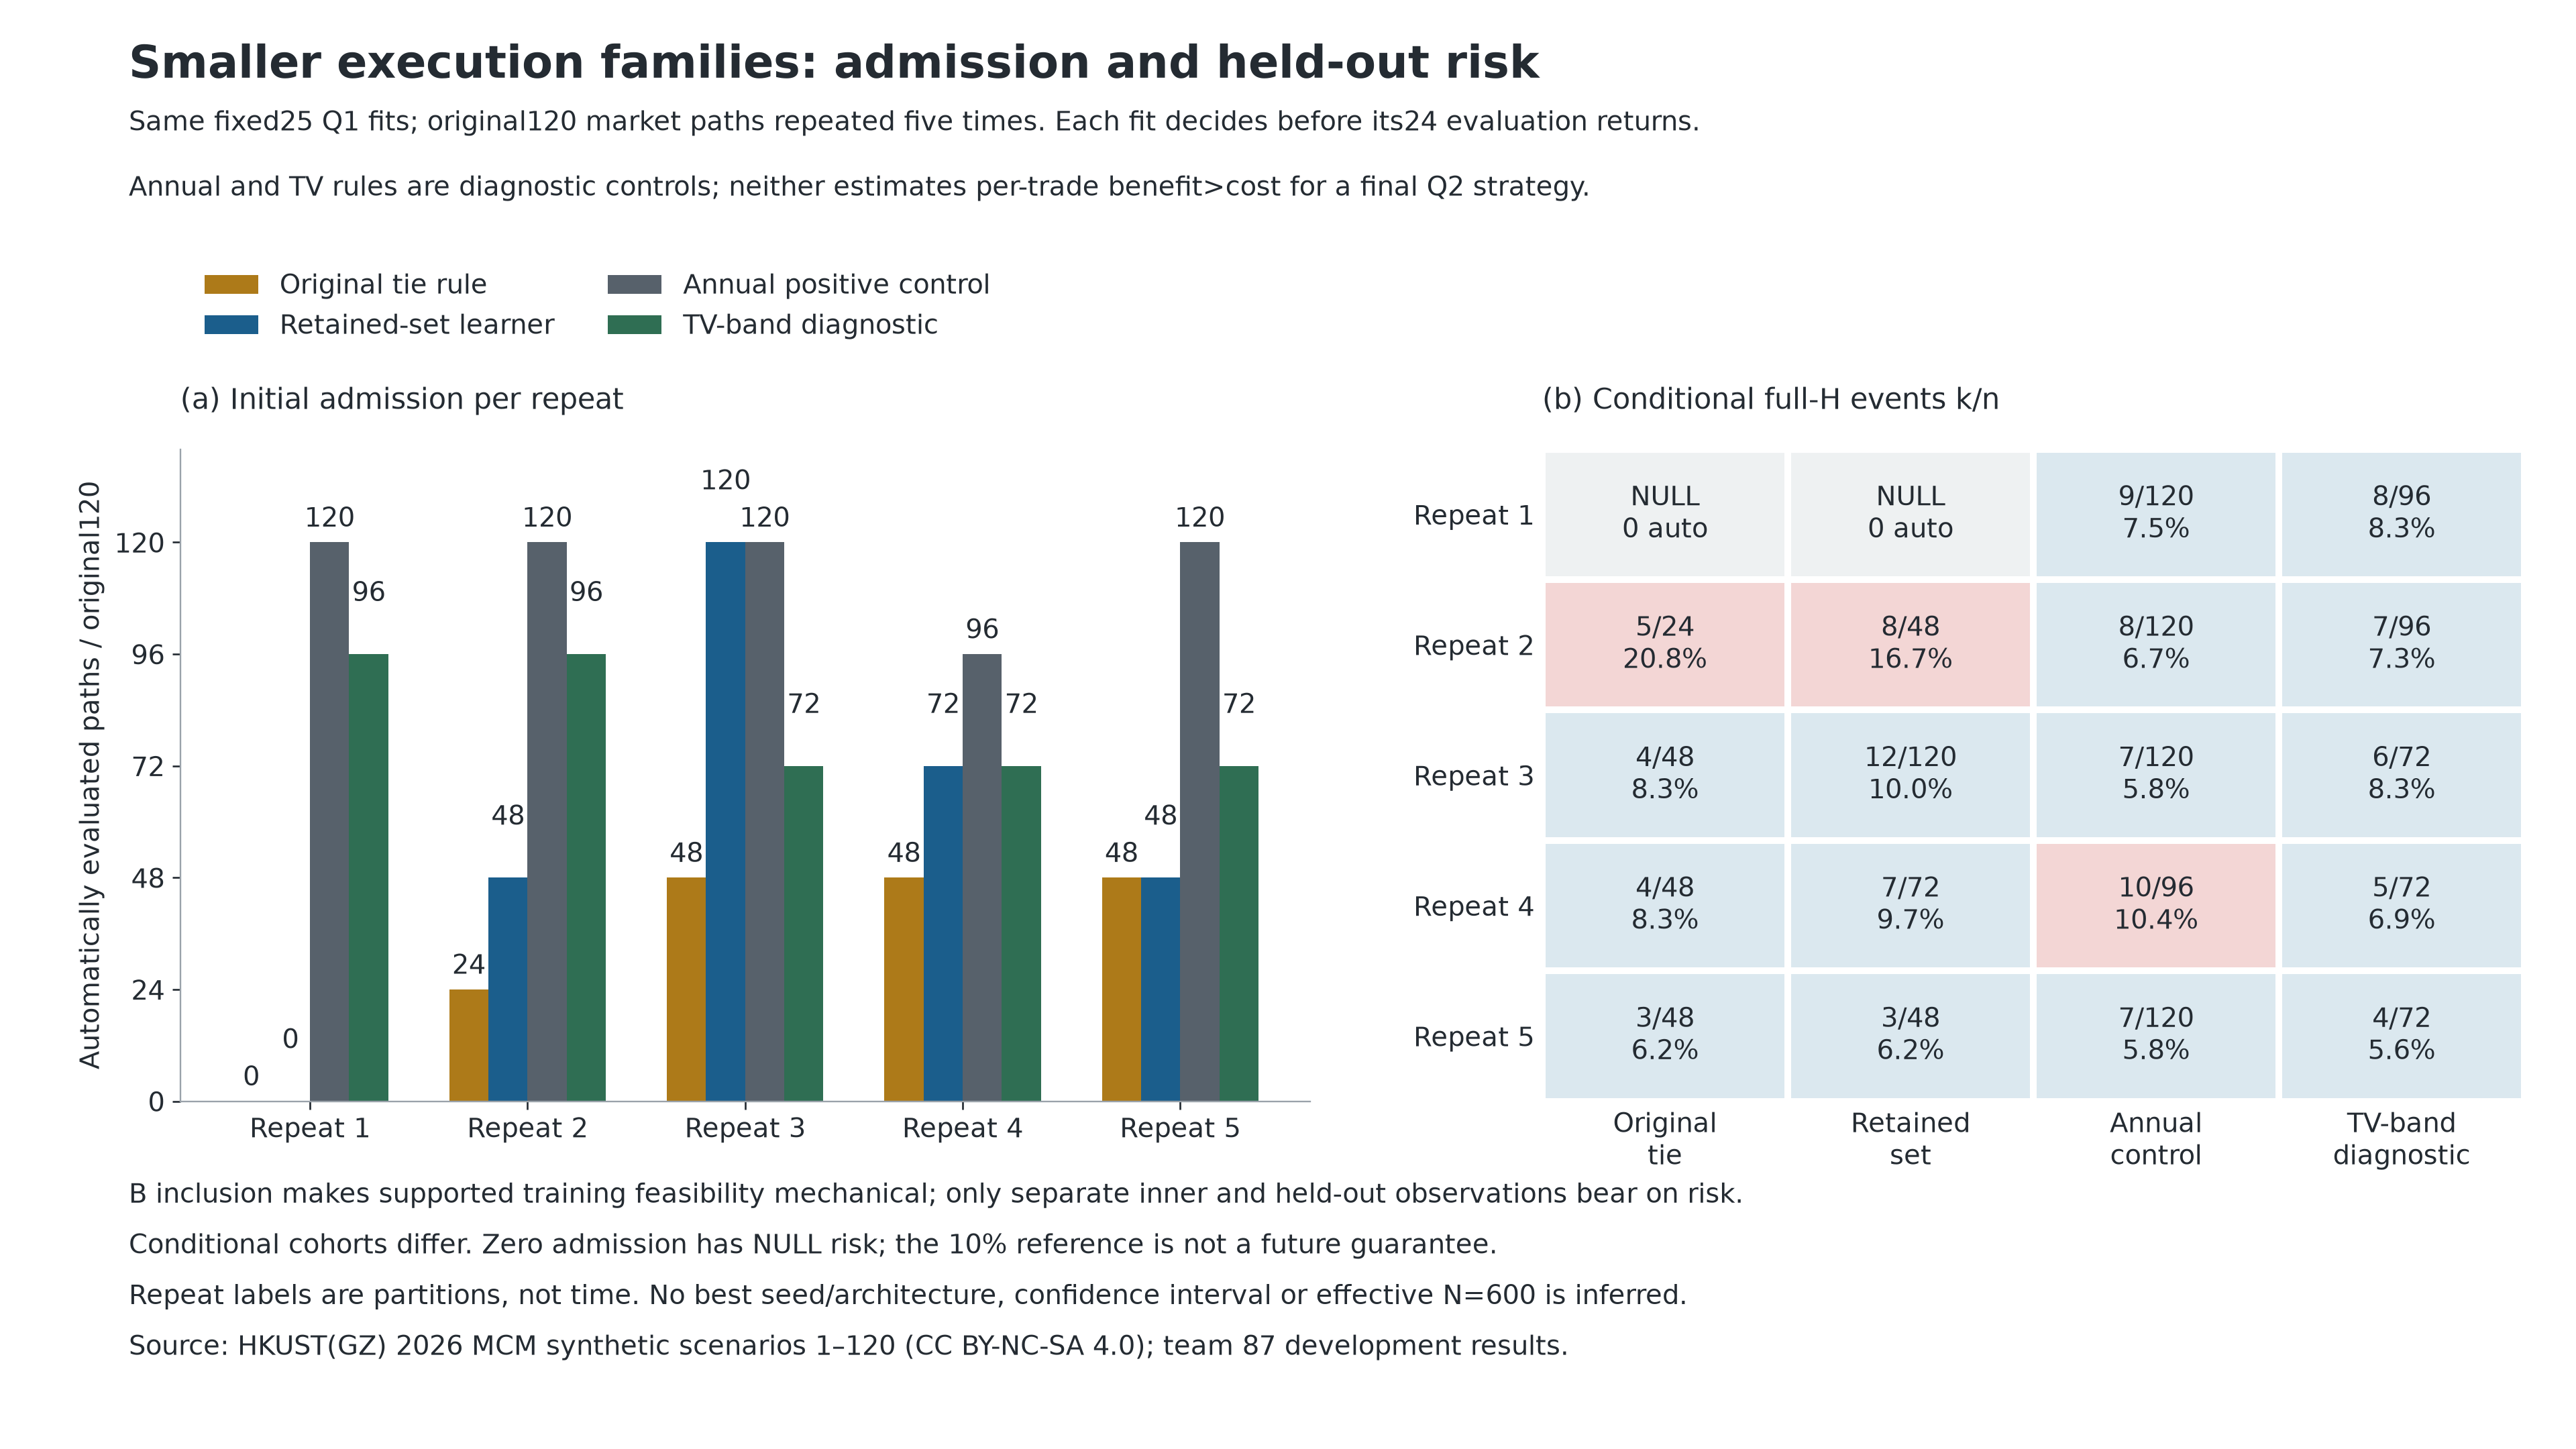

In [5]:
figure_path = ROOT/'research/figures/simple_execution/01_simple_controls_and_learners.png'
figure_bytes = base64.b64encode(figure_path.read_bytes()).decode('ascii')
display(HTML('<img alt="原120开发路径五次重复下四架构的准入数量与条件超限，零准入为NULL；新年度和TV控制均为诊断对照" '
             'src="data:image/png;base64,'+figure_bytes+'" style="max-width:100%;height:auto">'))

## 5. 金融差异只在相同自动子群上比较

每个配对都匹配重复、外折、上下文和原情景ID。自动与未自动路径之间的金融差值留空；年度B只是同目标的假想参照。与保留集合学习器比较的两个诊断控制，也只能在两者均自动执行的交集上算差。

年化对数增长与MDD的差仍以原分数为单位；下面显示为百分点。费用差以初始财富100的名义单位表示。平均差不含未准入路径，不是原120条全部路径的收益改进。

In [6]:
paired = pd.read_csv(SUMMARY/'paired_comparisons.csv')
common_paths = pd.read_csv(SUMMARY/'common_path_pairs.csv')
assert len(paired) == 30 and len(common_paths) == 3600
assert not common_paths[['repeat_id','outer_fold','context','scenario_id','left_policy','right_policy']].duplicated().any()
deltas = [name for name in common_paths if name.startswith('delta_')]
assert common_paths.loc[~common_paths.common_auto, deltas+['left_breach','right_breach']].isna().all().all()
view = paired.copy()
view['left_policy'] = view.left_policy.map(labels)
view['right_policy'] = view.right_policy.map(labels)
for field in ['mean_delta_log_growth','mean_delta_mdd']: view[field] *= 100
for right, group in view.groupby('right_policy', sort=False):
    print('右侧比较对象：'+right)
    show(group[['repeat_id','left_policy','common_auto_n','left_breach_n','right_breach_n',
                'mean_delta_log_growth','mean_delta_mdd','mean_delta_nominal_fees']].rename(columns={
        'repeat_id':'重复','left_policy':'左侧架构','common_auto_n':'共同自动_n',
        'left_breach_n':'左超限_k','right_breach_n':'右超限_k',
        'mean_delta_log_growth':'年化对数增长差_pp','mean_delta_mdd':'MDD差_pp','mean_delta_nominal_fees':'名义费用差'}),
        {'年化对数增长差_pp':'{:+.3f}','MDD差_pp':'{:+.3f}','名义费用差':'{:+.4f}'})

右侧比较对象：同目标年度等待假想参照


重复,左侧架构,共同自动_n,左超限_k,右超限_k,年化对数增长差_pp,MDD差_pp,名义费用差
1,原并列规则学习器,0,—,—,—,—,—
1,保留最优集合学习器,0,—,—,—,—,—
1,年度正对照,120,9.000000,9.000000,+0.000,+0.000,+0.0000
1,TV带宽诊断,96,8.000000,7.000000,+0.054,+0.363,-0.2599
2,原并列规则学习器,24,5.000000,4.000000,+0.327,+1.993,-0.2461
2,保留最优集合学习器,48,8.000000,5.000000,+0.314,+2.204,-0.2744
2,年度正对照,120,8.000000,8.000000,+0.000,+0.000,+0.0000
2,TV带宽诊断,96,7.000000,7.000000,+0.069,+0.256,-0.2409
3,原并列规则学习器,48,4.000000,2.000000,+0.269,+1.554,-0.3717
3,保留最优集合学习器,120,12.000000,7.000000,+0.338,+1.850,-0.3369


右侧比较对象：保留最优集合学习器


重复,左侧架构,共同自动_n,左超限_k,右超限_k,年化对数增长差_pp,MDD差_pp,名义费用差
1,年度正对照,0,—,—,—,—,—
1,TV带宽诊断,0,—,—,—,—,—
2,年度正对照,48,5.000000,8.000000,-0.314,-2.204,+0.2744
2,TV带宽诊断,24,4.000000,5.000000,-0.203,-1.589,-0.1718
3,年度正对照,120,7.000000,12.000000,-0.338,-1.850,+0.3369
3,TV带宽诊断,72,6.000000,8.000000,-0.265,-1.221,+0.1267
4,年度正对照,48,4.000000,6.000000,-0.393,-2.420,+0.3330
4,TV带宽诊断,48,2.000000,4.000000,-0.302,-2.483,+0.1193
5,年度正对照,48,2.000000,3.000000,-0.341,-2.073,+0.3820
5,TV带宽诊断,48,2.000000,3.000000,-0.291,-1.675,+0.2296


## 6. 分开观察内层门槛与最终准入

“训练族中包含B”与“内层通过”是不同陈述。内层对每个架构自己的U检验原期限事件，最终仍可能因Q1分类、内层证据或最终训练可行性而Review。下面只统计已保存决策，不在结果上重新排序候选、放宽门槛或挑选架构。

In [7]:
inner_gates = pd.read_csv(STUDY/'inner_gate_summaries.csv.gz')
final_admission = pd.read_csv(STUDY/'fit_admission.csv.gz')
assert len(inner_gates) == 50 and len(final_admission) == 50
assert not inner_gates[['context','policy']].duplicated().any()
gate_counts = inner_gates.groupby(['policy','eligible','reason'],dropna=False).size().rename('拟合数').reset_index()
gate_counts['policy'] = gate_counts.policy.map(labels)
show(gate_counts.rename(columns={'policy':'架构','eligible':'内层通过','reason':'内层原因'}))
decisions = final_admission.groupby(['policy','execution_status','selected_threshold'],dropna=False).size().rename('拟合数').reset_index()
decisions['policy'] = decisions.policy.map(labels)
show(decisions.rename(columns={'policy':'架构','execution_status':'最终状态','selected_threshold':'已选TV阈值'}),{'已选TV阈值':'{:.0%}'})
print('阈值频数不是可识别的风险偏好；不同阈值也不必然意味着不同动作。')

架构,内层通过,内层原因,拟合数
年度正对照,False,inner_absolute_risk_exceeds_reference,1
年度正对照,True,passed_inner_gate,24
TV带宽诊断,False,inner_risk_exceeds_same_U_B,8
TV带宽诊断,True,passed_inner_gate,17


架构,最终状态,已选TV阈值,拟合数
年度正对照,automated,0%,24
年度正对照,execution_review,—,1
TV带宽诊断,automated,0%,3
TV带宽诊断,automated,5%,6
TV带宽诊断,automated,10%,8
TV带宽诊断,execution_review,—,8


阈值频数不是可识别的风险偏好；不同阈值也不必然意味着不同动作。


### 条件分母不能省略：第四次重复的解释实例

年度正对照第4次的自动子群是10/96，而全部120条B假想参照是10/120；年度正对照所拒绝的24条路径，保存的B假想结果恰好没有事件。前两者条件比例的不同来自**准入群体变化**，不能据此把年度执行本身称为比同路径B更危险，更不能利用留出部分恰好0事件而倒过来放宽内层门槛或补上被拒服务的收益。

唯一年度拒绝是第4次第5折：内层10/96超过整数上限9。相同拟合的TV内层是8，既不超过9，也不超过同U的B事件10，所以TV按自己的门槛准入，最终选5%带宽；这不是年度控制拒绝后自动转入TV的兜底。

TV八次拒绝均是内层比同U的B多1次事件，绝对10%门槛没有超。最终“无训练候选”的失败为0，符合B包含的构造性质，不能把这个0解释为未来风险或完整学习流程已稳定。

In [8]:
witness_gates = inner_gates.loc[inner_gates.context.eq('stability_r4_outer5')].copy()
assert len(witness_gates) == 2
show(witness_gates[['policy','auto_inner_n','selected_breach_count','same_U_B_breach_count',
                   'absolute_alpha_count_cap','eligible']].replace({'policy':labels}).rename(columns={
    'policy':'架构','auto_inner_n':'内层U大小','selected_breach_count':'候选事件',
    'same_U_B_breach_count':'同U_B事件','absolute_alpha_count_cap':'绝对事件上限','eligible':'通过'}))
tv_rejected = inner_gates.loc[inner_gates.policy.eq('drift_band_gated_diagnostic') & ~inner_gates.eligible]
assert len(tv_rejected) == 8
assert (tv_rejected.selected_breach_count-tv_rejected.same_U_B_breach_count).eq(1).all()
assert tv_rejected.selected_breach_count.le(tv_rejected.absolute_alpha_count_cap).all()
assert not final_admission.execution_reason.eq('no_admissible_training_candidate').any()
physical_rows = pd.read_csv(STUDY/'client_paths.csv.gz')
r4 = physical_rows.loc[physical_rows.repeat_id.eq(4)]
annual_r4 = r4.loc[r4.policy.eq('annual_gated_diagnostic')]
annual_auto = annual_r4.loc[annual_r4.assigned]
refused_ids = set(annual_r4.loc[~annual_r4.assigned,'scenario_id'])
B_r4 = r4.loc[r4.policy.eq('annual_then_pending') & r4.assigned]
B_same = B_r4.loc[B_r4.scenario_id.isin(annual_auto.scenario_id)]
B_refused = B_r4.loc[B_r4.scenario_id.isin(refused_ids)]
witness = []
for name, group, hypothetical in [('年度自动子群',annual_auto,False),
    ('B在相同自动子群',B_same,True),('B在全部原120情景',B_r4,True),
    ('B在被拒24情景（仅假想）',B_refused,True)]:
    k = int(group.breach.sum())
    witness.append({'集合':name,'可用n':len(group),'事件k':k,'条件k/n':k/len(group), '仅假想参照':hypothetical})
witness.append({'集合':'被拒24条的客户服务结果','可用n':0,'事件k':None,'条件k/n':None,'仅假想参照':False})
show(pd.DataFrame(witness), {'条件k/n':'{:.2%}'})
assert len(B_refused) == 24 and int(B_refused.breach.sum()) == 0
assert annual_r4.loc[~annual_r4.assigned,['log_growth','mdd','nominal_fees','breach']].isna().all().all()
print('这个例子解释条件分母；不据已看到的留出事件改门槛，不作风险校准或总体代表性的证明。')

架构,内层U大小,候选事件,同U_B事件,绝对事件上限,通过
年度正对照,96,10,10,9,False
TV带宽诊断,96,8,10,9,True


集合,可用n,事件k,条件k/n,仅假想参照
年度自动子群,96,10.000000,10.42%,False
B在相同自动子群,96,10.000000,10.42%,True
B在全部原120情景,120,10.000000,8.33%,True
B在被拒24情景（仅假想）,24,0.000000,0.00%,True
被拒24条的客户服务结果,0,—,—,False


这个例子解释条件分母；不据已看到的留出事件改门槛，不作风险校准或总体代表性的证明。


## 7. 当前证据能支持的判断

**年度正对照：训练包含B，仍没有留出安全保证。** 25个拟合中24个准入。第4次为10/96=10.42%，超过10%参考。这直接说明训练构造性质与实际留出风险不是一回事。

**TV诊断：更少交易伴随可辨认的风险代价。** 25个拟合中17个准入、8个Review；复核原因是inner_risk_exceeds_same_U_B：8次。这不是程序漏算或看见某条评估情景后筛选，而是该拟合在看收益前统一执行的自身内层门槛。

在各重复自己的共同自动子群上，TV相对B的平均年化对数增长高0.054—0.092个百分点，平均MDD也高0.199—0.363个百分点，平均名义费用差为-0.262至-0.210（初始100）。这里的增长数字是百分点／年对数增长，不能扩大十倍或称终值收益增幅。

五组共同子群的事件为：8/96 对 7/96；7/96 对 7/96；6/72 对 5/72；5/72 对 5/72；4/72 对 2/72（TV在左、B在右）。其中3组TV事件更多、2组持平；五组平均MDD均更高，不能称对B实现风险支配。尤其不能将某次TV的条件比例与覆盖更多情景的年度正对照原表比例直接相减来宣称风险改善。

五次TV条件超限均低于10%，但不能据此称策略已安全或选择最终架构。 全部情景此前已用于开发，训练集重叠，自动子群不同，而且这些规则仍未估计逐笔benefit>cost。当前判断是保留年度与TV为诊断工具，并继续研究交易收益—成本及风险的联合判断，暂不批准最终控制器。

这次对照把候选族、排序与准入规则一并定义成两个更简单的架构，所以架构差异不能单独归因于“移除了预测”。训练约束、B的包含关系与实际留出事件应分别解释；五次重复的描述性差异也不等于未来10%的保证。

判断下一步是否保留某个机制，应同时考虑准入、共同自动子群的增长／风险／费用，以及题目要求的逐笔收益—成本判断。不能因年度或TV对照在某个指标上表现较好，就跳过后者。本笔记没有确定最终控制器，也没有新论文或CMT提交。

下一步若构建新的逐笔收益—成本或条件情景方法，需要另列假设和冻结完整学习—准入流程，再检查原期限事件；当前对照仅帮助定位问题。

## 8. 审计与复现记录

审计核对的是数值、状态、选择和门槛的一致性。算法独立重算不等于独立人工评审，也不等于真实市场分布已校准。下方路径与哈希支持回查原文件；完整重跑由冻结runner与其协议负责，本笔记只重放保存结果的说明与图表。

本轮检查范围是：9个代码单元从头执行、保存输出和HTML静态结构核对，以及嵌入PNG的实际图像检查。整页HTML的浏览器预览受本地文件访问策略限制，未记录为整页视觉检查通过。

数据来源：HKUST(GZ) 2026 MCM SafeInvest synthetic scenarios 1—120，CC BY-NC-SA 4.0；研究记录：Team87。所有费用、漂移、原期限事件定义保留在对应协议和源码中。

In [9]:
evidence_paths = [
    ROOT/'docs/simple_execution_comparison_protocol.json',
    ROOT/'docs/simple_drift_cost_interpretation.json',
    ROOT/'docs/simple_execution_diagnostic_judgment.json',
    STUDY/'manifest.json', STUDY/'independent_audit.json', SUMMARY/'manifest.json',
    ROOT/'scripts/run_simple_execution_comparison.py',
    ROOT/'scripts/summarize_simple_execution_comparison.py',
    ROOT/'scripts/build_simple_execution_notebook.py', figure_path]
show(pd.DataFrame([{'来源路径':str(path.relative_to(ROOT)),'SHA256':sha(path)} for path in evidence_paths]))
print(f"独立数值核对：{independent_audit['checks_passed']:,}项；这不是风险分布保证。")
print('执行状态：只读保存结果的检查与呈现；没有新拟合、交易模拟、参数选择或最终情景读取。')

来源路径,SHA256
docs/simple_execution_comparison_protocol.json,f4c399807679ef18119b56af28358b7a1b35d2acf0bdaf32c4b0de03d233d9db
docs/simple_drift_cost_interpretation.json,ec9fa5044c8eeddaf1f062cc69d8a0ed813e6287587beee83267ff79bcb97d14
docs/simple_execution_diagnostic_judgment.json,fde34c7e5f294f708b9ac4fbcb81383b793815c3175fc803546ee2dd67d29893
results/model_review/simple_execution_comparison_v1/manifest.json,056a6389cdf13dc0f3e16feac618ab8fa215f4bc228cc6eec18066e53f5dd31b
results/model_review/simple_execution_comparison_v1/independent_audit.json,065544294539a333a43535c5e287f92b31ea70a81344d0323ff8a743561ab22d
results/model_review/simple_execution_summary_v1/manifest.json,165916baf3d181b43dfe26d3759e7744eb3476b84462905a8b9f09aa1d2be4f3
scripts/run_simple_execution_comparison.py,b82071d44305d6aceefacce83e49275a0ac4b7ad5cc59cc71d62258a4f99de36
scripts/summarize_simple_execution_comparison.py,110abd1289c465f35f97b4ecb45fe46b9f6bba17f80779cebfebe350fffda689
scripts/build_simple_execution_notebook.py,547ce82a96eb4744acd4990e2886595f115915fc5520cbaf090e26dea1974dc8
research/figures/simple_execution/01_simple_controls_and_learners.png,77d05ce6bd0462b1e15a7e8322935a34ab7c43208bbad0d82444db3ad96fdb52


独立数值核对：5,100,120项；这不是风险分布保证。
执行状态：只读保存结果的检查与呈现；没有新拟合、交易模拟、参数选择或最终情景读取。
